# Capítulo 3 — Los datos y su análisis

Reproduce los resultados numéricos y las figuras principales del Capítulo 3:

| Sección | Resultado | Celda |
|---|---|---|
| 3.2.2–3.2.3 | Exponente espectral βc en la banda confiable (Fig. 3.2) y submuestreo de 11 628 combinaciones | §1 |
| 3.2.4 | DFA sobre G(t) y sobre el residuo (Tabla 3.1, Fig. 3.3) | §2 |
| 3.3.1–3.3.5 | Indicador S(t) y su exponente espectral (Figs. 3.4–3.7) | §3 |
| 3.3.6 | Fenómeno del alba e ingestas en el sujeto DBT2-05 (Figs. 3.8, 3.12) | §4 |
| 3.4 | Exponente y tiempo de Lyapunov (Tabla 3.4) | §5 |
| 3.5 | Plano H × C (Fig. 3.15) | §6 |
| 3.5.4 | Norma del vector estacionario de la OPTM (Tabla 3.5) | §7 |
| 3.6 | Parámetros de incrustación y reconstrucción de Takens (Figs. 3.16–3.17) | §8 |

**Datos.** Registros de 1200 muestras (12,5 días, Δt = 15 min). Como en la tesis, el
contraste usa los 5 registros NDBT2 reales y un subconjunto de 5 registros DBT2 ubicados en
los percentiles 10, 30, 50, 70 y 90 de βc de banda completa, elegido entre 19 registros
DBT2 (el Capítulo 3 no incluyó DBT2-11). Ver `REPRODUCIBILIDAD.md` sobre el registro
DBT2-06, idéntico a DBT2-04.

Al final del notebook una celda compara cada cifra con el valor publicado.

In [1]:
import sys, os, itertools
from pathlib import Path
if "google.colab" in sys.modules and not Path("glucosa").exists():
    os.system("git clone -q https://github.com/aamadioaaa/tesis-glucosa-sdde.git")
    os.chdir("tesis-glucosa-sdde/notebooks")
sys.path.insert(0, str(Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()))

from decimal import Decimal, ROUND_HALF_UP
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from scipy import stats

from glucosa import datos, espectral, ordinal, no_lineal, detector
from glucosa.forzamiento import forzamiento, forzamiento_espectral_cap3

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .25})
C_ND, C_D = "#1b7837", "#d95f02"
OUT = datos.carpeta_resultados(3)

S_IDS = datos.IDS_NDBT2_REALES
E_IDS = [i for i in datos.IDS_DBT2 if i != 11]          # 19 registros, como en la tesis
G = {("NDBT2", i): datos.cargar_cgm("NDBT2", i) for i in S_IDS}
G.update({("DBT2", i): datos.cargar_cgm("DBT2", i) for i in E_IDS})

# Subconjunto representativo del DBT2 (percentiles 10–90 de βc de banda completa)
bg = np.array([espectral.beta_banda_completa(G["DBT2", i]) for i in E_IDS])
orden = np.argsort(bg, kind="stable")
E_REP = [E_IDS[orden[int(round(q / 100 * (len(E_IDS) - 1)))]] for q in (10, 30, 50, 70, 90)]
print("Subconjunto representativo DBT2:", E_REP)


def compara(nd, db, nombre=""):
    nd, db = np.asarray(nd), np.asarray(db)
    u, pu = stats.mannwhitneyu(db, nd)
    t, pt = stats.ttest_ind(db, nd, equal_var=False)
    d = (db.mean() - nd.mean()) / np.sqrt((nd.var(ddof=1) + db.var(ddof=1)) / 2)
    print(f"{nombre:28s} NDBT2 = {nd.mean():.3f} ± {nd.std(ddof=1):.3f} | DBT2 = {db.mean():.3f} ± "
          f"{db.std(ddof=1):.3f} | U = {u:.0f}, p = {pu:.4f} | t = {t:.2f}, p = {pt:.4f} | d = {d:.2f}")
    return dict(nd_media=nd.mean(), nd_de=nd.std(ddof=1), db_media=db.mean(), db_de=db.std(ddof=1),
                U=u, p_MW=pu, t=t, p_t=pt, d=d)


def submuestreo(todos, nd, nombre=""):
    todos, nd = np.asarray(todos), np.asarray(nd)
    comb = list(itertools.combinations(range(len(todos)), 5))
    delta = np.array([todos[list(c)].mean() - nd.mean() for c in comb])
    p = np.array([stats.mannwhitneyu(todos[list(c)], nd).pvalue for c in comb])
    print(f"{nombre:28s} {len(comb)} combinaciones: Δ mediana = {np.median(delta):.3f}, "
          f"rango [{delta.min():.3f}, {delta.max():.3f}], significativas = {100 * np.mean(p < 0.05):.1f} %")
    return delta, p


RES = {}

Subconjunto representativo DBT2: [18, 2, 14, 17, 6]


## 0. Registros de 24 h (Sec. 3.1, Fig. 3.1)
Primer día de NDBT2-01 y de DBT2-02 (96 muestras de 15 min).

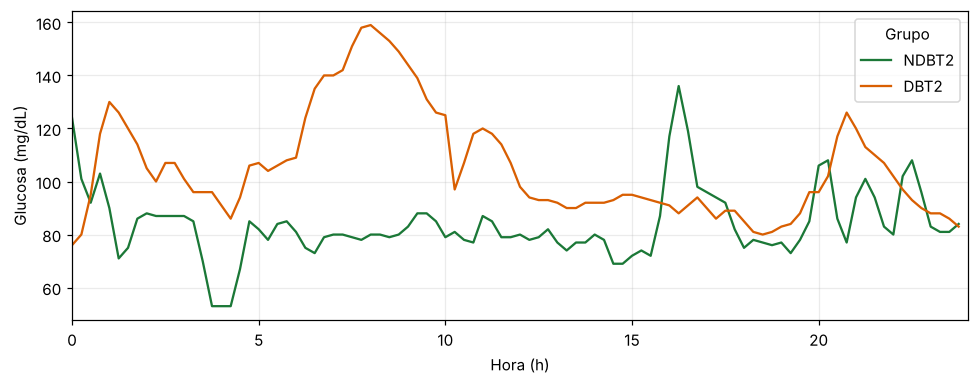

In [2]:
h24 = np.arange(96) / 4
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.plot(h24, datos.cargar_cgm("NDBT2", 1)[:96], color=C_ND, label="NDBT2")
ax.plot(h24, datos.cargar_cgm("DBT2", 2)[:96], color=C_D, label="DBT2")
ax.set(xlabel="Hora (h)", ylabel="Glucosa (mg/dL)", xlim=(0, 24)); ax.legend(title="Grupo")
fig.tight_layout(); fig.savefig(OUT / "figura_3_1_registros_24h.png", dpi=200); plt.show()

## 1. Exponente espectral βc (Secs. 3.2.2–3.2.3, Fig. 3.2)
Welch (256 puntos, 50 % de solapamiento) sobre la señal centrada; ajuste log-log en la
banda confiable 0,08–1 ciclos/h (períodos de 12 a 1 h).

In [3]:
bc_nd = [espectral.beta_welch(G["NDBT2", i]) for i in S_IDS]
bc_d = [espectral.beta_welch(G["DBT2", i]) for i in E_REP]
bc_todos = [espectral.beta_welch(G["DBT2", i]) for i in E_IDS]
RES["bc"] = compara(bc_nd, bc_d, "βc banda confiable")
RES["bc_sub"], RES["bc_sub_p"] = submuestreo(bc_todos, bc_nd, "βc submuestreo")
RES["bc_full"] = compara([espectral.beta_banda_completa(G["NDBT2", i]) for i in S_IDS],
                         [espectral.beta_banda_completa(G["DBT2", i]) for i in E_REP], "βc banda completa")
gnd, gd = RES["bc_full"]["nd_media"], RES["bc_full"]["db_media"]
print(f"βc banda completa: NDBT2 = {gnd:.2f}, DBT2 = {gd:.2f}, Δ = {gd - gnd:.2f}")

βc banda confiable           NDBT2 = 1.283 ± 0.164 | DBT2 = 2.605 ± 0.163 | U = 25, p = 0.0079 | t = 12.78, p = 0.0000 | d = 8.08


βc submuestreo               11628 combinaciones: Δ mediana = 1.295, rango [0.960, 1.729], significativas = 100.0 %
βc banda completa            NDBT2 = 2.060 ± 0.136 | DBT2 = 2.546 ± 0.171 | U = 25, p = 0.0079 | t = 4.98, p = 0.0012 | d = 3.15
βc banda completa: NDBT2 = 2.06, DBT2 = 2.55, Δ = 0.49


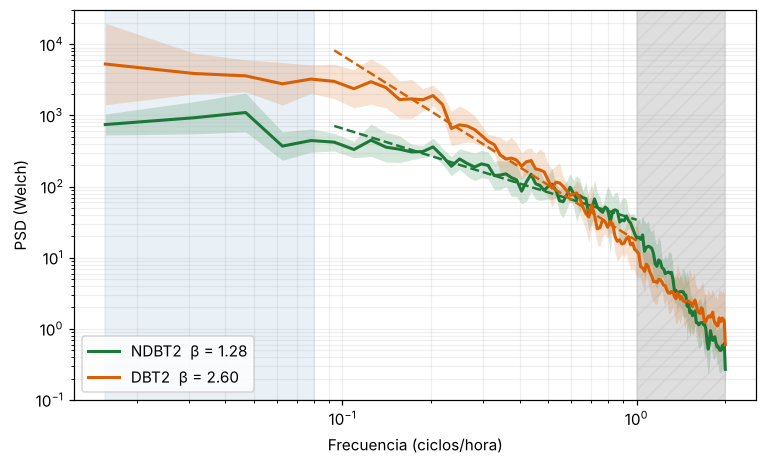

In [4]:
def banda_log(ps, m):
    L = np.log(np.array([p[1] for p in ps])[:, m]); s = L.std(0, ddof=1)
    return np.exp(L.mean(0)), np.exp(L.mean(0) - s), np.exp(L.mean(0) + s)

def figura_espectro(senales_nd, senales_d, b_nd, b_d, ylim=None, ruta=None, etiqueta="PSD (Welch)"):
    ps_nd = [espectral.psd(x) for x in senales_nd]; ps_d = [espectral.psd(x) for x in senales_d]
    f = ps_nd[0][0]; m = f > 0; fm = f[m]
    lo, hi = espectral.BANDA_CONFIABLE; reg = (fm >= lo) & (fm <= hi)
    fig, ax = plt.subplots(figsize=(8, 4.6))
    ax.axvspan(fm.min(), lo, color="#dbe7f0", alpha=.6)
    ax.axvspan(hi, fm.max(), color="0.82", alpha=.7, hatch="//")
    for ps, b, c, lab in [(ps_nd, b_nd, C_ND, "NDBT2"), (ps_d, b_d, C_D, "DBT2")]:
        med, inf, sup = banda_log(ps, m)
        ax.fill_between(fm, inf, sup, color=c, alpha=.18, lw=0)
        ax.loglog(fm, med, color=c, lw=2, label=f"{lab}  β = {np.mean(b):.2f}")
        k = np.exp(np.mean(np.log(med[reg]) + np.mean(b) * np.log(fm[reg])))
        ax.loglog(fm[reg], k * fm[reg] ** (-np.mean(b)), "--", color=c, lw=1.6)
    if ylim: ax.set_ylim(*ylim)
    ax.set_xlabel("Frecuencia (ciclos/hora)"); ax.set_ylabel(etiqueta); ax.legend(loc="lower left")
    ax.grid(True, which="both", alpha=.2)
    if ruta: fig.savefig(ruta, dpi=200, bbox_inches="tight")
    plt.show()

figura_espectro([G["NDBT2", i] for i in S_IDS], [G["DBT2", i] for i in E_REP], bc_nd, bc_d,
                ylim=(1e-1, 3e4), ruta=OUT / "figura_3_2_psd_glucosa.png")

## 2. DFA — exponente de Hurst (Sec. 3.2.4, Tabla 3.1, Fig. 3.3)
DFA de orden 1 en escalas de 8 a 288 muestras (≈ 2–72 h) sobre G(t) y sobre su componente
fluctuante (G menos su tendencia de Savitzky–Golay, ventana 49, orden 3).

In [5]:
a_g = {k: espectral.dfa(v) for k, v in G.items()}
a_r = {k: espectral.dfa(espectral.residuo_fluctuante(v)) for k, v in G.items()}
RES["dfa_G"] = compara([a_g["NDBT2", i] for i in S_IDS], [a_g["DBT2", i] for i in E_REP], "DFA α sobre G(t)")
sub_g, p_g = submuestreo([a_g["DBT2", i] for i in E_IDS], [a_g["NDBT2", i] for i in S_IDS], "DFA G(t) submuestreo")
RES["dfa_R"] = compara([a_r["NDBT2", i] for i in S_IDS], [a_r["DBT2", i] for i in E_REP], "DFA α sobre el residuo")
sub_r, p_r = submuestreo([a_r["DBT2", i] for i in E_IDS], [a_r["NDBT2", i] for i in S_IDS], "DFA residuo submuestreo")
RES["dfa_sub"] = (100 * np.mean(p_g < .05), 100 * np.mean(p_r < .05), np.median(sub_r))

tabla_31 = pd.DataFrame({
    "Señal": ["G(t)", "G(t)", "Residuo", "Residuo"], "Grupo": ["NDBT2", "DBT2"] * 2,
    "α media": [RES["dfa_G"]["nd_media"], RES["dfa_G"]["db_media"], RES["dfa_R"]["nd_media"], RES["dfa_R"]["db_media"]],
    "α DE": [RES["dfa_G"]["nd_de"], RES["dfa_G"]["db_de"], RES["dfa_R"]["nd_de"], RES["dfa_R"]["db_de"]]}).round(3)
tabla_31.to_csv(OUT / "tabla_3_1_dfa.csv", index=False); tabla_31

DFA α sobre G(t)             NDBT2 = 0.818 ± 0.052 | DBT2 = 0.895 ± 0.121 | U = 16, p = 0.5476 | t = 1.31, p = 0.2426 | d = 0.83


DFA G(t) submuestreo         11628 combinaciones: Δ mediana = 0.056, rango [-0.072, 0.205], significativas = 2.3 %
DFA α sobre el residuo       NDBT2 = 0.294 ± 0.016 | DBT2 = 0.374 ± 0.038 | U = 25, p = 0.0079 | t = 4.30, p = 0.0066 | d = 2.72


DFA residuo submuestreo      11628 combinaciones: Δ mediana = 0.074, rango [0.032, 0.124], significativas = 73.7 %


,Señal,Grupo,α media,α DE
0,G(t),NDBT2,0.818,0.052
1,G(t),DBT2,0.895,0.121
2,Residuo,NDBT2,0.294,0.016
3,Residuo,DBT2,0.374,0.038


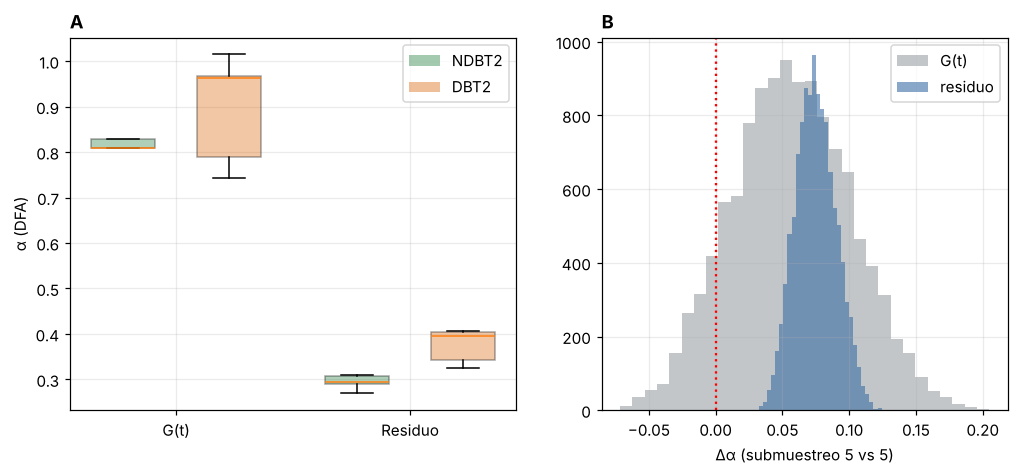

In [6]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4.4), gridspec_kw=dict(width_ratios=[1.1, 1]))
vals = [[a_g["NDBT2", i] for i in S_IDS], [a_g["DBT2", i] for i in E_REP],
        [a_r["NDBT2", i] for i in S_IDS], [a_r["DBT2", i] for i in E_REP]]
bp = a1.boxplot(vals, positions=[1, 2, 3.2, 4.2], widths=.6, patch_artist=True, showfliers=False)
for b, c in zip(bp["boxes"], [C_ND, C_D, C_ND, C_D]): b.set_facecolor(c); b.set_alpha(.35)
a1.set_xticks([1.5, 3.7]); a1.set_xticklabels(["G(t)", "Residuo"]); a1.set_ylabel("α (DFA)")
a1.legend(handles=[Patch(fc=C_ND, alpha=.4, label="NDBT2"), Patch(fc=C_D, alpha=.4, label="DBT2")])
a1.set_title("A", loc="left", fontweight="bold")
a2.hist(sub_g, bins=30, color="#9aa0a6", alpha=.6, label="G(t)")
a2.hist(sub_r, bins=30, color="#3b6ea5", alpha=.6, label="residuo")
a2.axvline(0, color="red", ls=":"); a2.set_xlabel("Δα (submuestreo 5 vs 5)"); a2.legend()
a2.set_title("B", loc="left", fontweight="bold")
fig.savefig(OUT / "figura_3_3_dfa.png", dpi=200, bbox_inches="tight"); plt.show()

## 3. Indicador de forzamiento metabólico S(t) (Secs. 3.3.1–3.3.5)
Figuras 3.4–3.6 para un día del sujeto DBT2-05, y exponente espectral de S(t) (Fig. 3.7).

*Nota:* el exponente espectral de S(t) de la Sección 3.3.5 se calculó con la variante
`forzamiento_espectral_cap3` (ventana de 17 muestras, corte DCT del 10 %, sin raíz). La
versión usada por el modelo (Caps. 4–7) es `forzamiento` (ventana de 10, corte del 35 %,
con raíz, ec. 3.13). Ambas se documentan en `glucosa/forzamiento.py`.

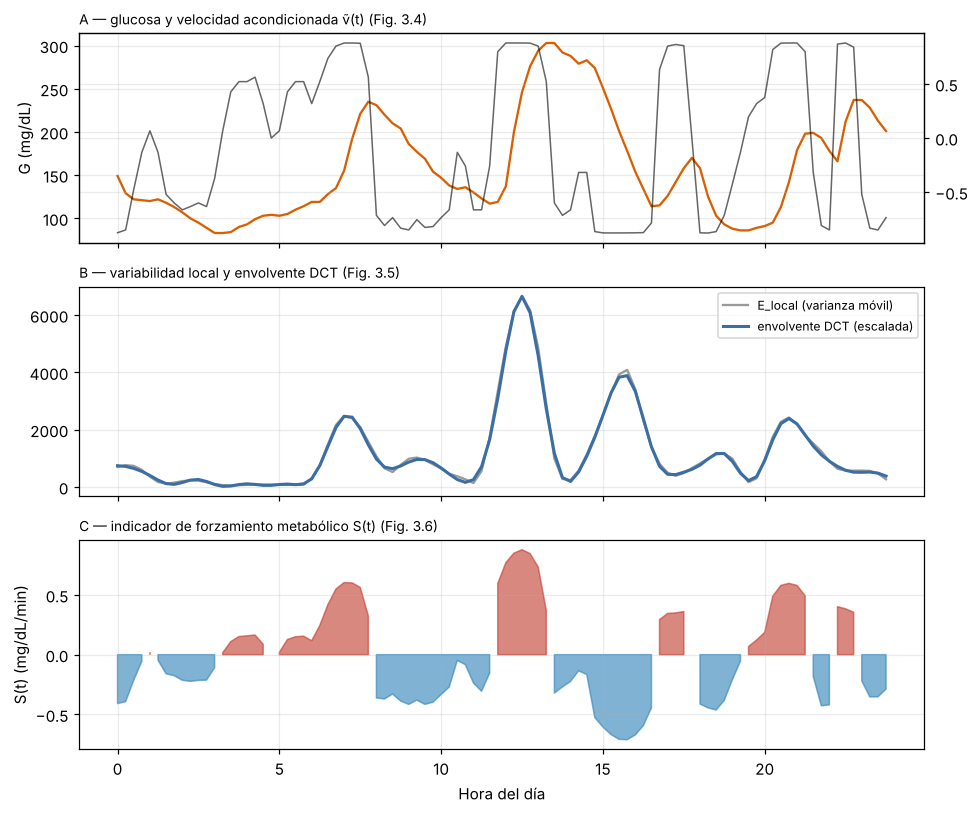

In [7]:
g5 = datos.cargar_cgm("DBT2", 5, 1152)
s5, comp = forzamiento(g5, devolver_componentes=True)
dia = slice(96 * 3, 96 * 4); horas = np.arange(96) / 4
fig, ax = plt.subplots(3, 1, figsize=(9, 7.5), sharex=True)
ax[0].plot(horas, g5[dia], color=C_D); ax[0].set_ylabel("G (mg/dL)")
ax[0].twinx().plot(horas, comp["v_acond"][dia], color="k", lw=1, alpha=.6)
ax[0].set_title("A — glucosa y velocidad acondicionada ṽ(t) (Fig. 3.4)", loc="left", fontsize=9)
ax[1].plot(horas, comp["E_local"][dia], color="0.6", label="E_local (varianza móvil)")
ax[1].plot(horas, comp["E_norm"][dia] * comp["E_local"][dia].max(), color="#3b6ea5", lw=2, label="envolvente DCT (escalada)")
ax[1].legend(fontsize=8); ax[1].set_title("B — variabilidad local y envolvente DCT (Fig. 3.5)", loc="left", fontsize=9)
ax[2].fill_between(horas, 0, s5[dia], where=s5[dia] > 0, color="#c0392b", alpha=.6)
ax[2].fill_between(horas, 0, s5[dia], where=s5[dia] < 0, color="#2c7fb8", alpha=.6)
ax[2].set_ylabel("S(t) (mg/dL/min)"); ax[2].set_xlabel("Hora del día")
ax[2].set_title("C — indicador de forzamiento metabólico S(t) (Fig. 3.6)", loc="left", fontsize=9)
fig.tight_layout(); fig.savefig(OUT / "figuras_3_4_a_3_6_forzamiento.png", dpi=200); plt.show()

β de S(t) banda confiable    NDBT2 = 0.115 ± 0.153 | DBT2 = 1.278 ± 0.223 | U = 25, p = 0.0079 | t = 9.61, p = 0.0000 | d = 6.08
Δβ glucosa = 1.32;  Δβ forzamiento = 1.16


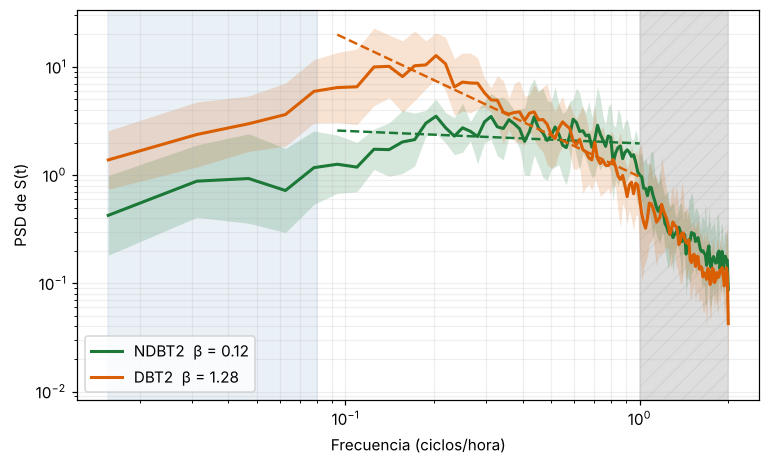

In [8]:
sS = {k: forzamiento_espectral_cap3(v) for k, v in G.items()}
bS_nd = [espectral.beta_welch(sS["NDBT2", i] - sS["NDBT2", i].mean()) for i in S_IDS]
bS_d = [espectral.beta_welch(sS["DBT2", i] - sS["DBT2", i].mean()) for i in E_REP]
RES["bS"] = compara(bS_nd, bS_d, "β de S(t) banda confiable")
RES["bS_full"] = (np.mean([espectral.beta_banda_completa(sS["DBT2", i] - sS["DBT2", i].mean()) for i in E_REP])
                  - np.mean([espectral.beta_banda_completa(sS["NDBT2", i] - sS["NDBT2", i].mean()) for i in S_IDS]))
print(f"Δβ glucosa = {np.mean(bc_d) - np.mean(bc_nd):.2f};  Δβ forzamiento = {np.mean(bS_d) - np.mean(bS_nd):.2f}")
figura_espectro([sS["NDBT2", i] for i in S_IDS], [sS["DBT2", i] for i in E_REP], bS_nd, bS_d,
                ruta=OUT / "figura_3_7_psd_forzamiento.png", etiqueta="PSD de S(t)")

## 4. Fenómeno del alba e ingestas en el sujeto DBT2-05 (Sec. 3.3.6)
Implementación de las ecuaciones (3.14)–(3.35b). Los parámetros de implementación
(núcleo de Morlet, normalización de W, ε) están declaradas en `glucosa/detector.py`.

In [9]:
alba = detector.detectar_alba(g5, s5)
tabla_alba = pd.DataFrame([vars(v) for v in alba])[["dia", "delta_g", "I_G", "I_S", "W_media", "minimo_previo", "categoria"]]
tabla_alba.round(3).to_csv(OUT / "alba_DBT2_05.csv", index=False)
print(tabla_alba["categoria"].value_counts().to_dict())
tabla_alba.round(2)

{'moderada': 5, 'fuerte': 4, 'posible': 2, 'no compatible': 1}


,dia,delta_g,I_G,I_S,W_media,minimo_previo,categoria
0,1,58.0,0.98,0.78,0.03,113.0,moderada
1,2,52.0,0.95,0.64,0.04,96.0,moderada
2,3,107.0,0.86,0.51,0.18,140.0,fuerte
3,4,148.0,1.00,0.81,0.23,89.0,fuerte
4,5,82.0,0.10,0.25,0.13,161.0,posible
5,6,36.0,0.98,0.84,0.10,87.0,moderada
6,7,32.0,0.85,0.82,0.04,115.0,moderada
7,8,132.0,1.00,0.68,0.22,99.0,fuerte
8,9,120.0,1.00,0.80,0.22,135.0,fuerte
9,10,42.0,0.99,0.10,0.20,116.0,posible


In [10]:
ing = detector.detectar_ingestas(g5, s5)
tabla_ing = pd.DataFrame([vars(v) for v in ing])
tabla_ing.round(3).to_csv(OUT / "ingestas_DBT2_05.csv", index=False)
cat = tabla_ing["categoria"].value_counts().to_dict()
print("Ventanas compatibles con ingesta:", len(ing), cat)
for c in ("fuerte", "moderada"):
    sub = tabla_ing[tabla_ing.categoria == c]
    dg = Decimal(repr(float(sub.delta_g_max.mean()))).quantize(Decimal("0.1"), ROUND_HALF_UP)   # redondeo «mitad hacia arriba»
    print(f"  {c}: ΔG_max medio = {dg} mg/dL, I_S medio = {sub.I_S.mean():.2f}")
RES["ingesta"] = (len(ing), cat)

Ventanas compatibles con ingesta: 31 {'posible': 14, 'moderada': 9, 'fuerte': 8}
  fuerte: ΔG_max medio = 155.3 mg/dL, I_S medio = 0.77
  moderada: ΔG_max medio = 135.6 mg/dL, I_S medio = 0.68


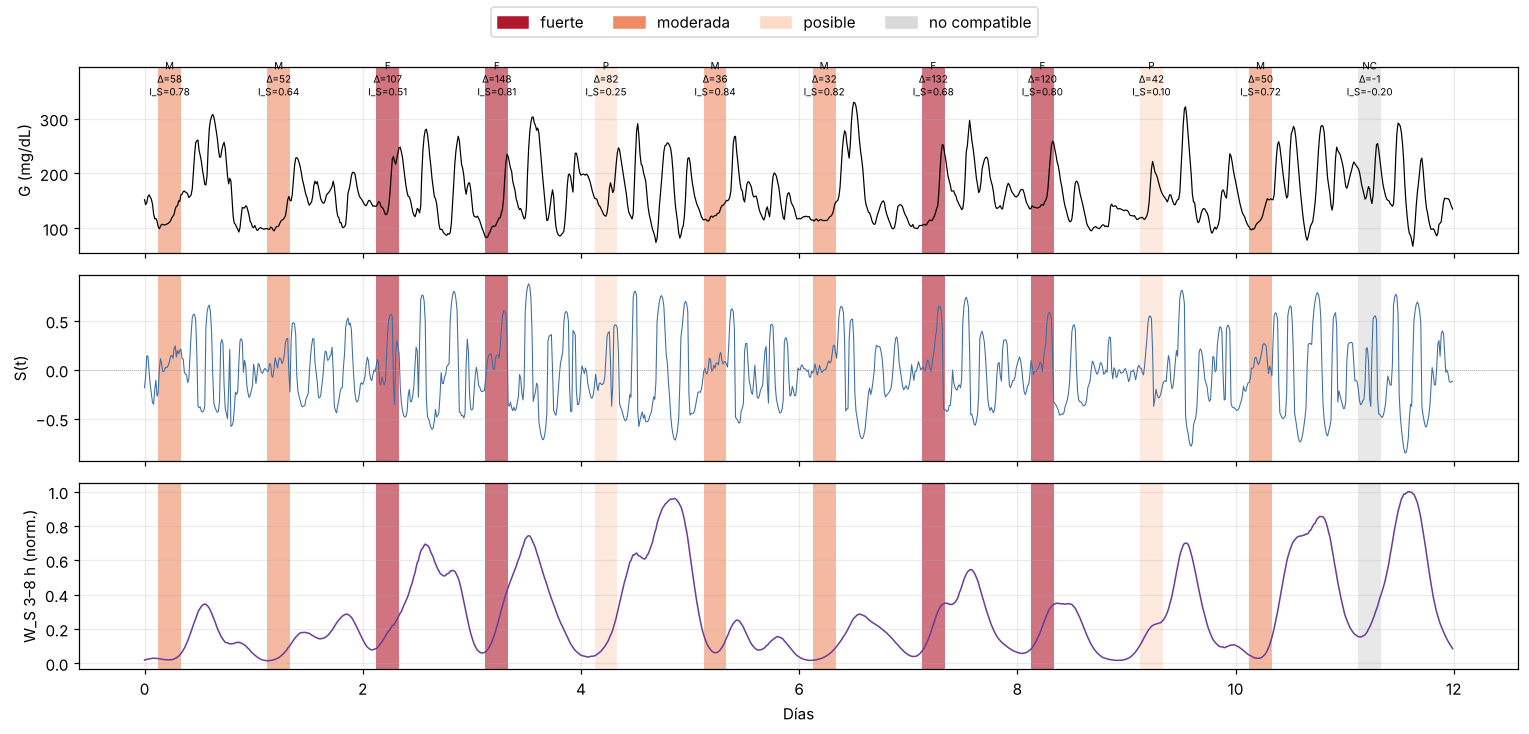

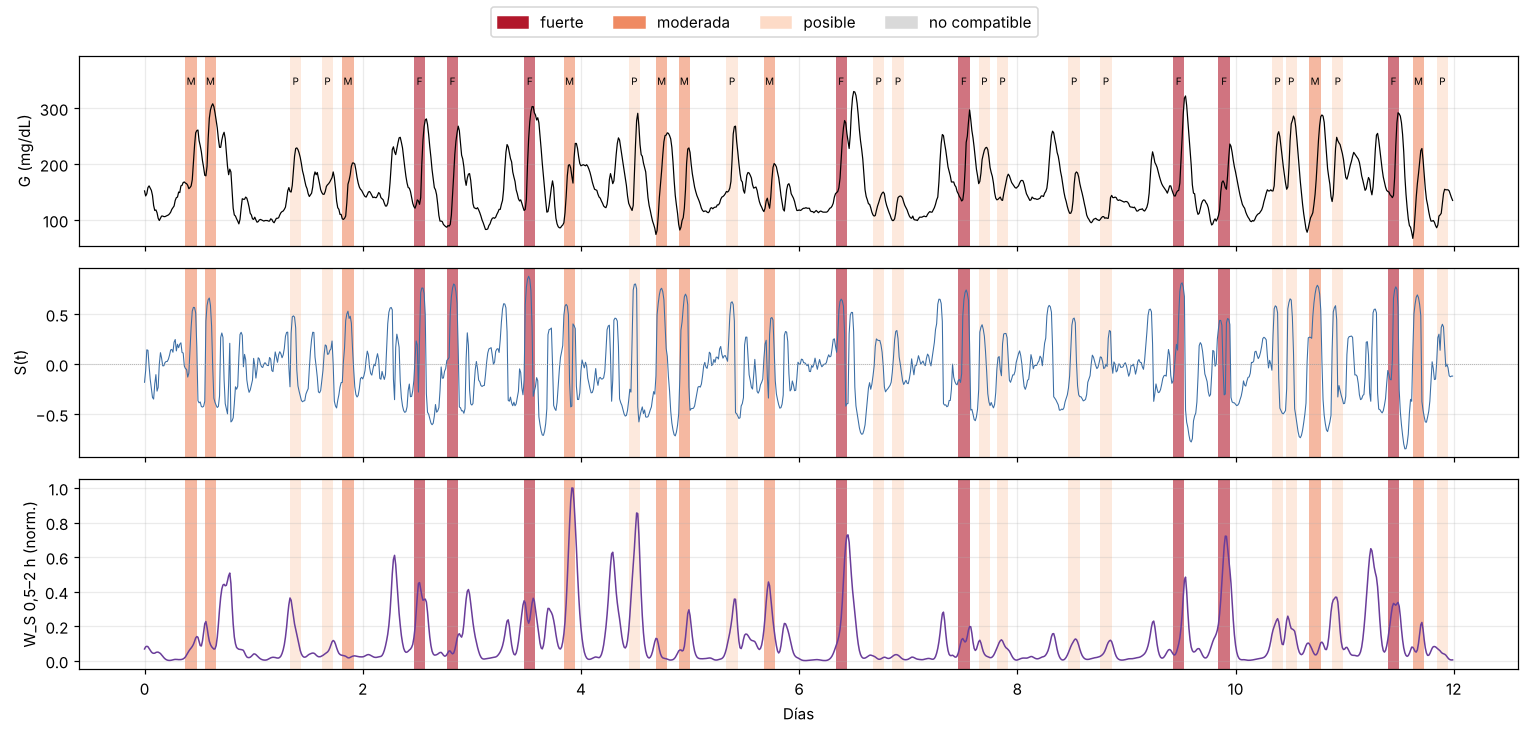

In [11]:
w_alba = detector.energia_banda(s5, detector.BANDA_ALBA)
w_ing = detector.energia_banda(s5, detector.BANDA_INGESTA)
t_d = np.arange(len(g5)) / 96
colores = {"fuerte": "#b2182b", "moderada": "#ef8a62", "posible": "#fddbc7", "no compatible": "0.85"}
letra = {"fuerte": "F", "moderada": "M", "posible": "P", "no compatible": "NC"}
def figura_eventos(eventos, w, etiqueta_w, rotulo, archivo):
    fig, ax = plt.subplots(3, 1, figsize=(14, 6.7), sharex=True)
    ax[0].plot(t_d, g5, color="k", lw=.8); ax[0].set_ylabel("G (mg/dL)")
    ax[1].plot(t_d, s5, color="#3b6ea5", lw=.7); ax[1].axhline(0, color="0.6", lw=.5, ls=":"); ax[1].set_ylabel("S(t)")
    ax[2].plot(t_d, w, color="#6a3d9a", lw=1); ax[2].set_ylabel(etiqueta_w)
    ytop = g5.max() * 1.02
    for v in eventos:
        for a_ in ax:
            a_.axvspan(v.inicio / 96, v.fin / 96, color=colores[v.categoria], alpha=.6, lw=0)
        ax[0].text((v.inicio + v.fin) / 192, ytop, rotulo(v), ha="center", va="bottom", fontsize=6.5, linespacing=1.1)
    ax[0].set_ylim(top=ytop * 1.17); ax[2].set_xlabel("Días")
    fig.legend(handles=[Patch(color=c, label=k) for k, c in colores.items()], loc="upper center", ncol=4)
    fig.tight_layout(rect=(0, 0, 1, .95)); fig.savefig(OUT / archivo, dpi=200); plt.show()

# Figura 3.8 — fenómeno del alba (rótulo: categoría, ΔG e I_S de cada día)
figura_eventos(alba, w_alba, "W_S 3–8 h (norm.)",
               lambda v: f"{letra[v.categoria]}\nΔ={v.delta_g:.0f}\nI_S={v.I_S:.2f}", "figura_3_8_alba_DBT2_05.png")
# Figura 3.12 — eventos compatibles con ingesta (rótulo: categoría)
figura_eventos(ing, w_ing, "W_S 0,5–2 h (norm.)", lambda v: letra[v.categoria], "figura_3_12_ingestas_DBT2_05.png")

### 4.1 Ejemplos y exclusión por hipoglucemia nocturna (Figs. 3.9–3.11 y 3.13)
El detector se aplica a los 12 días de los 19 registros DBT2 del capítulo. La gradación
fuerte/moderada/posible del alba es la de apoyo visual de la Tabla 3.3.

Sujetos con hipoglucemia nocturna (22–08 h): 9 de 19
Ventanas con ascenso precedidas por un mínimo < 70 mg/dL: 23; por debajo de 54: 3; mínimo 40 mg/dL
DBT2-05 (12 días): {'moderada': 5, 'fuerte': 4, 'posible': 2, 'no compatible': 1} | ΔG fuertes: [107, 148, 132, 120] | día 12: ΔG = -1, I_S = -0.20


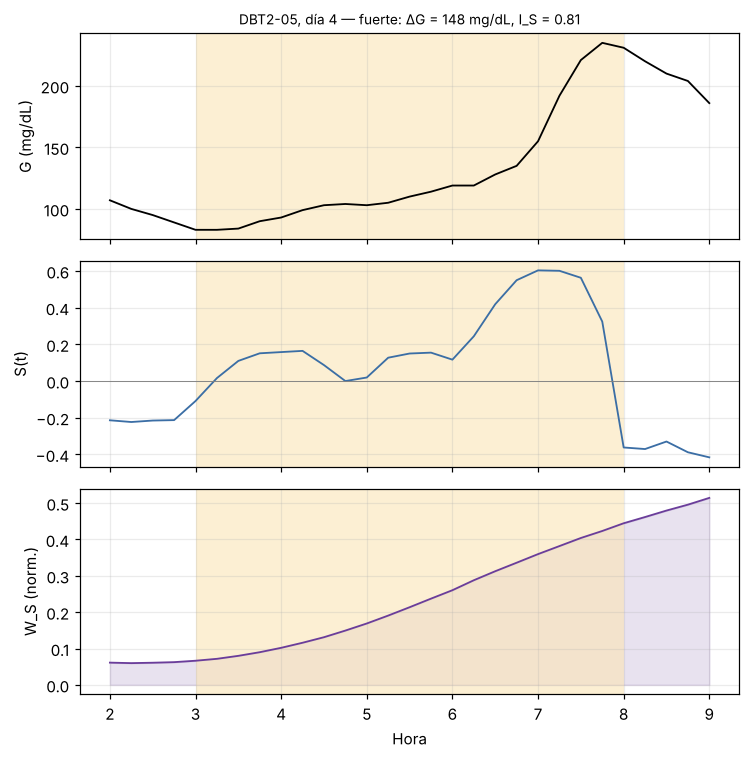

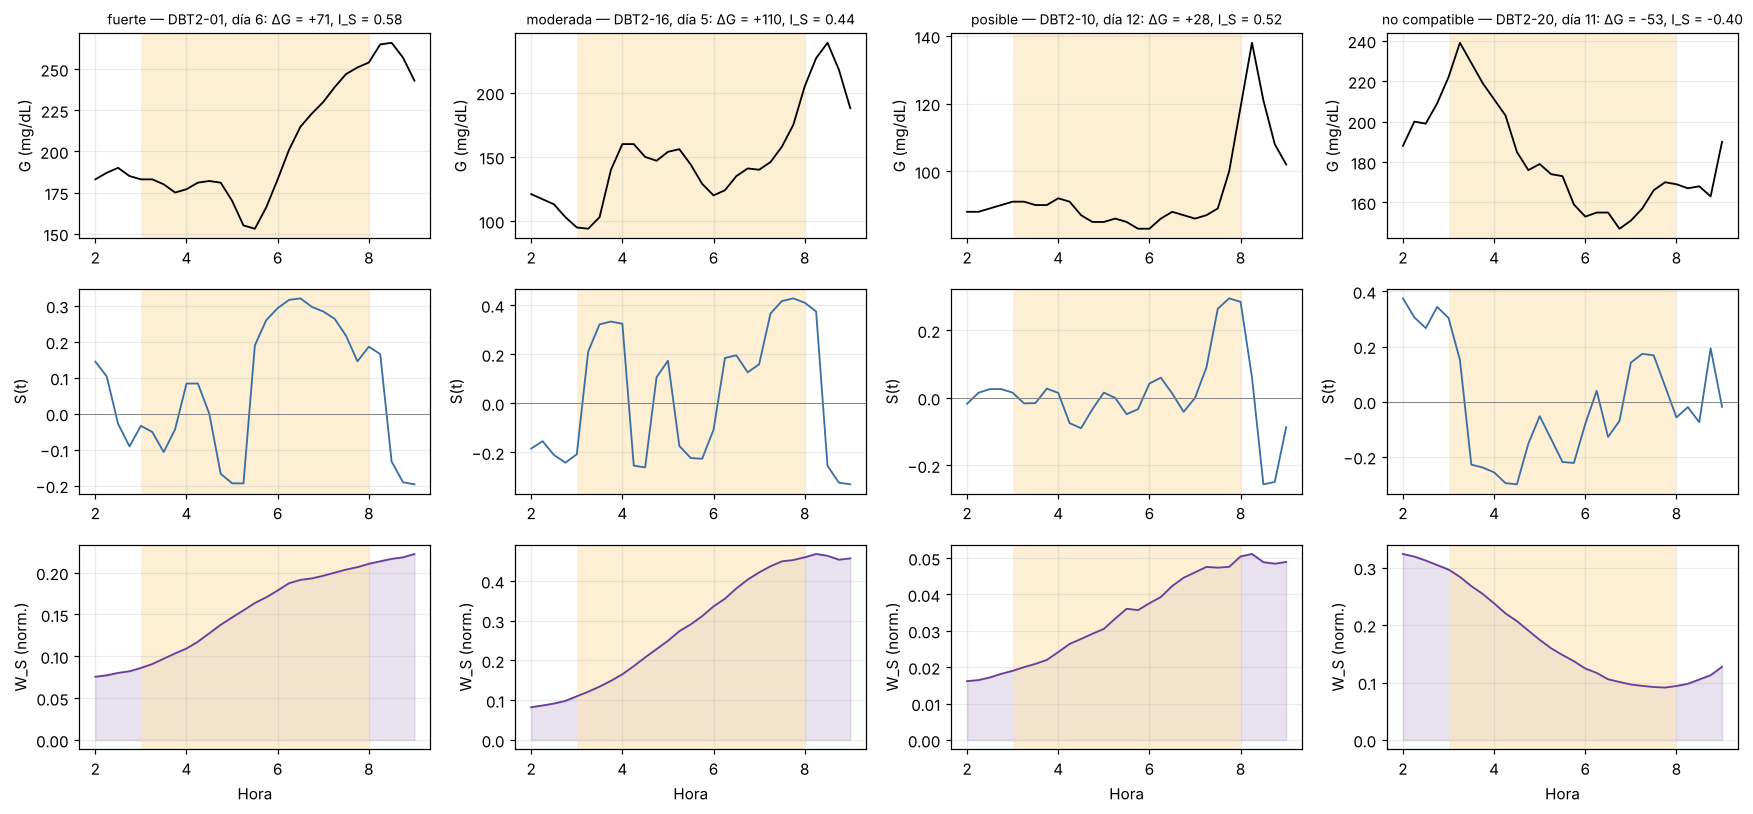

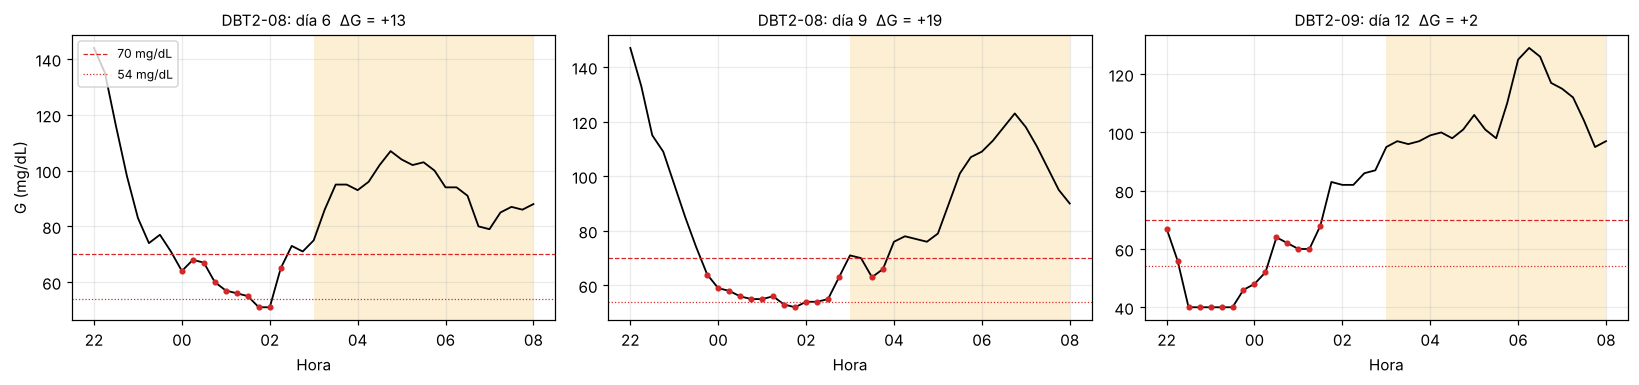

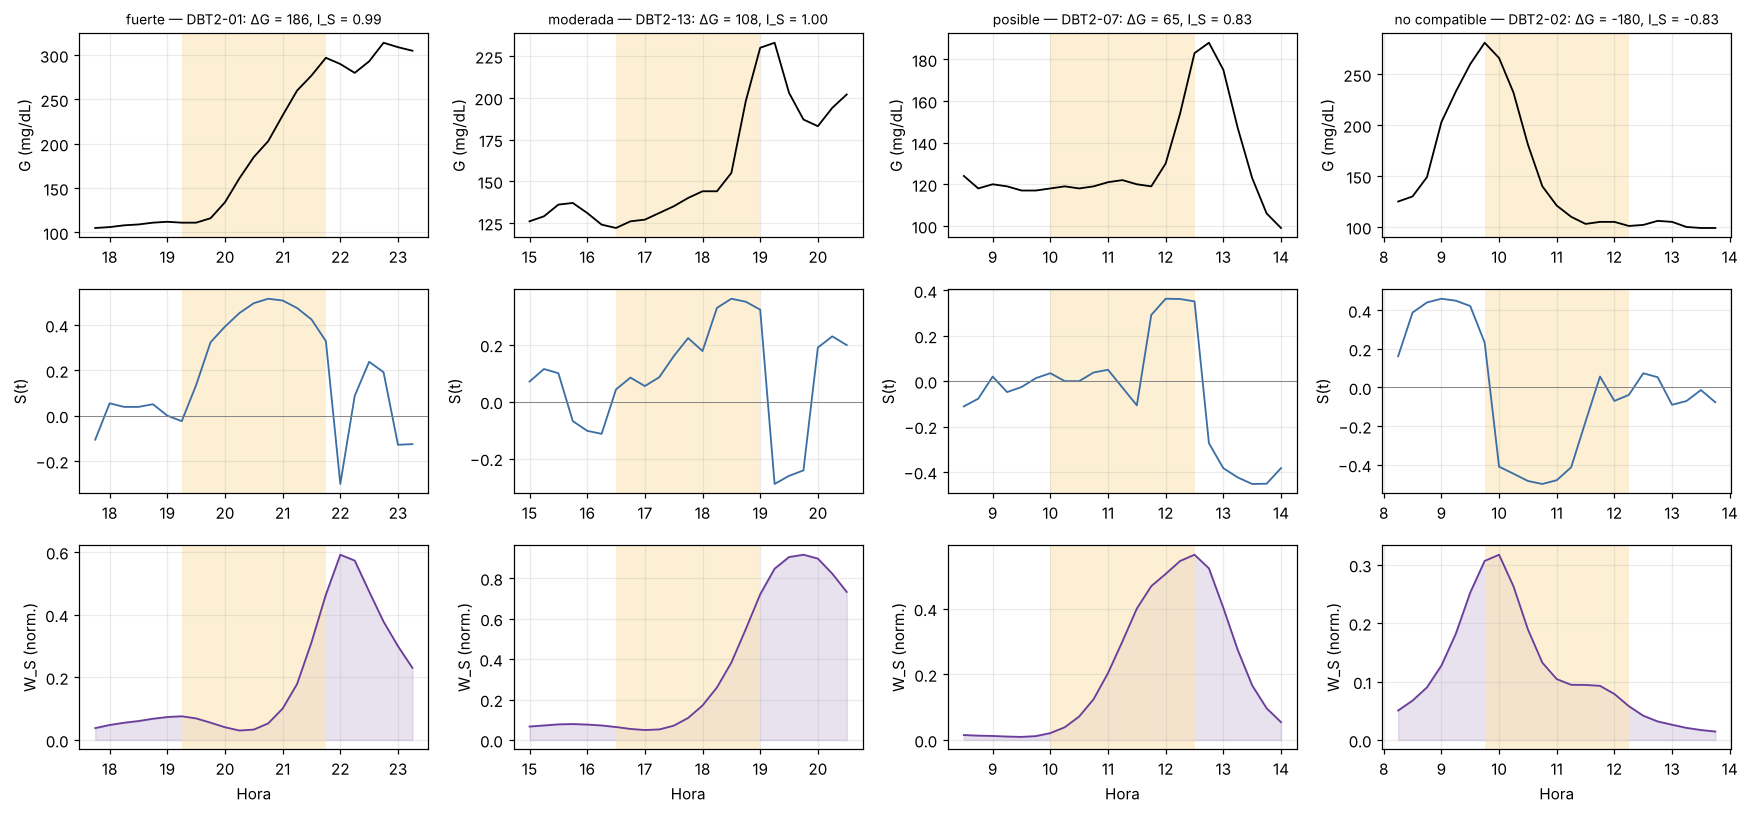

In [12]:
G12 = {i: datos.cargar_cgm("DBT2", i, 1152) for i in E_IDS}
S12 = {i: forzamiento(G12[i]) for i in E_IDS}
ALBA = {i: detector.detectar_alba(G12[i], S12[i]) for i in E_IDS}
ING = {i: detector.detectar_ingestas(G12[i], S12[i]) for i in E_IDS}
todas = pd.DataFrame([dict(sujeto=i, **vars(v)) for i in E_IDS for v in ALBA[i]])
previas = todas[(todas.minimo_previo < 70) & (todas.delta_g > 0)]
noct = sum(any(G12[i][((np.arange(1152) % 96) >= 88) | ((np.arange(1152) % 96) < 32)] < 70) for i in E_IDS)
print(f"Sujetos con hipoglucemia nocturna (22–08 h): {noct} de {len(E_IDS)}")
print(f"Ventanas con ascenso precedidas por un mínimo < 70 mg/dL: {len(previas)}; "
      f"por debajo de 54: {np.sum(previas.minimo_previo < 54)}; mínimo {previas.minimo_previo.min():.0f} mg/dL")
RES["hipo"] = (noct, len(previas), int(np.sum(previas.minimo_previo < 54)), previas.minimo_previo.min())
alba5 = todas[todas.sujeto == 5]
print("DBT2-05 (12 días):", alba5.categoria.value_counts().to_dict(),
      "| ΔG fuertes:", alba5[alba5.categoria == "fuerte"].delta_g.astype(int).tolist(),
      "| día 12: ΔG = %.0f, I_S = %.2f" % tuple(alba5[alba5.dia == 12][["delta_g", "I_S"]].iloc[0]))

W_ALBA = {i: detector.energia_banda(S12[i], detector.BANDA_ALBA) for i in E_IDS}
W_ING = {i: detector.energia_banda(S12[i], detector.BANDA_INGESTA) for i in E_IDS}


def panel_ventana(ax3, i, a, b, w, titulo, contexto=4, sombra="#fbe5b6", hipo=False):
    """Tres paneles (G, S, W) alrededor de la ventana [a, b] del registro i."""
    lo, hi = max(0, a - contexto), min(len(G12[i]), b + contexto + 1)
    t = (np.arange(lo, hi) % 96) / 4
    t = np.where(np.diff(np.r_[t[0], t]) < 0, t + 24, t); t = np.maximum.accumulate(t)
    g, s_, ww = G12[i][lo:hi], S12[i][lo:hi], w[lo:hi]
    ta, tb = t[a - lo], t[min(b, hi - 1) - lo]
    ax3[0].plot(t, g, "k", lw=1.2); ax3[1].plot(t, s_, color="#3b6ea5", lw=1.2); ax3[1].axhline(0, color="0.5", lw=.6)
    ax3[2].plot(t, ww, color="#6a3d9a", lw=1.2); ax3[2].fill_between(t, 0, ww, color="#6a3d9a", alpha=.15)
    for x in ax3:
        x.axvspan(ta, tb, color=sombra, alpha=.6, lw=0)
    if hipo:
        ax3[0].axhline(70, color="#d62728", ls="--", lw=.8); ax3[0].axhline(54, color="#d62728", ls=":", lw=.8)
        m = g < 70; ax3[0].plot(t[m], g[m], "o", color="#d62728", ms=3)
    ax3[0].set_title(titulo, fontsize=9)
    ax3[0].set_ylabel("G (mg/dL)"); ax3[1].set_ylabel("S(t)"); ax3[2].set_ylabel("W_S (norm.)"); ax3[2].set_xlabel("Hora")


# Figura 3.9 — evento fuerte aislado (DBT2-05, día 4)
v = [x for x in ALBA[5] if x.dia == 4][0]
fig, ax = plt.subplots(3, 1, figsize=(7, 7), sharex=True)
panel_ventana(ax, 5, v.inicio, v.fin, W_ALBA[5], f"DBT2-05, día 4 — fuerte: ΔG = {v.delta_g:.0f} mg/dL, I_S = {v.I_S:.2f}")
fig.tight_layout(); fig.savefig(OUT / "figura_3_9_alba_fuerte.png", dpi=200); plt.show()

# Figura 3.10 — un ejemplo por categoría, de sujetos distintos (el de mayor ΔG en cada una)
fig, ax = plt.subplots(3, 4, figsize=(16, 7.5))
usados = {5}
for col, cat_ in enumerate(["fuerte", "moderada", "posible", "no compatible"]):
    sub = todas[(todas.categoria == cat_) & ~todas.sujeto.isin(usados) & (todas.minimo_previo >= 70)]
    sub = sub.sort_values("delta_g", ascending=(cat_ == "no compatible"))
    f = sub.iloc[0]; usados.add(f.sujeto)
    panel_ventana(ax[:, col], f.sujeto, int(f.inicio), int(f.fin), W_ALBA[f.sujeto],
                  f"{cat_} — DBT2-{f.sujeto:02d}, día {f.dia}: ΔG = {f.delta_g:+.0f}, I_S = {f.I_S:.2f}")
fig.tight_layout(); fig.savefig(OUT / "figura_3_10_alba_clasificaciones.png", dpi=200); plt.show()

# Figura 3.11 — las tres ventanas descartadas con mínimo previo < 54 mg/dL
casos = previas[previas.minimo_previo < 54].sort_values(["sujeto", "dia"])
fig, ax = plt.subplots(1, len(casos), figsize=(5 * len(casos), 3.6), squeeze=False)
for k, (_, f) in enumerate(casos.iterrows()):
    a, b = int(f.inicio), int(f.fin); lo = max(0, a - 20); t = (np.arange(lo, b + 1) - a) / 4 + 3
    g = G12[f.sujeto][lo:b + 1]; x = ax[0, k]
    x.plot(t, g, "k", lw=1.2); x.axvspan(3, 8, color="#fbe5b6", alpha=.6, lw=0)
    x.axhline(70, color="#d62728", ls="--", lw=.8, label="70 mg/dL"); x.axhline(54, color="#d62728", ls=":", lw=.8, label="54 mg/dL")
    m = g < 70; x.plot(t[m], g[m], "o", color="#d62728", ms=3)
    x.set_xticks([-2, 0, 2, 4, 6, 8], ["22", "00", "02", "04", "06", "08"]); x.set_xlabel("Hora")
    x.set_title(f"DBT2-{f.sujeto:02d}: día {f.dia}  ΔG = {f.delta_g:+.0f}", fontsize=10)
ax[0, 0].set_ylabel("G (mg/dL)"); ax[0, 0].legend(loc="upper left", fontsize=8)
fig.tight_layout(); fig.savefig(OUT / "figura_3_11_exclusion_hipoglucemia.png", dpi=200); plt.show()

# Figura 3.13 — un ejemplo de ingesta por categoría, de sujetos distintos
ing_todas = pd.DataFrame([dict(sujeto=i, **vars(v)) for i in E_IDS for v in ING[i]])
fig, ax = plt.subplots(3, 4, figsize=(16, 7.5))
usados = {5}
for col, cat_ in enumerate(["fuerte", "moderada", "posible"]):
    sub = ing_todas[(ing_todas.categoria == cat_) & ~ing_todas.sujeto.isin(usados)].sort_values("Q", ascending=False)
    f = sub.iloc[0]; usados.add(f.sujeto)
    panel_ventana(ax[:, col], f.sujeto, int(f.inicio), int(f.fin), W_ING[f.sujeto],
                  f"{cat_} — DBT2-{f.sujeto:02d}: ΔG = {f.delta_g_max:.0f}, I_S = {f.I_S:.2f}", contexto=6)
# contraejemplo: ventana diurna de 2,5 h con descenso de G (no compatible)
i_nc = next(i for i in E_IDS if i not in usados)
cands = [(a, G12[i_nc][a + 10] - G12[i_nc][a]) for a in range(0, 1142) if 32 <= a % 96 <= 86]
a_nc = min(cands, key=lambda c: c[1])[0]
ig = detector.indice_predominio(G12[i_nc][a_nc:a_nc + 11] - G12[i_nc][a_nc]); is_ = detector.indice_predominio(S12[i_nc][a_nc:a_nc + 11])
panel_ventana(ax[:, 3], i_nc, a_nc, a_nc + 10, W_ING[i_nc],
              f"no compatible — DBT2-{i_nc:02d}: ΔG = {G12[i_nc][a_nc + 10] - G12[i_nc][a_nc]:+.0f}, I_S = {is_:.2f}", contexto=6)
fig.tight_layout(); fig.savefig(OUT / "figura_3_13_ingesta_clasificaciones.png", dpi=200); plt.show()

## 5. Exponente y tiempo de Lyapunov (Sec. 3.4, Tabla 3.4)
Rosenstein (`nolds.lyap_r`, emb_dim = 3, lag = 1, min_tsep = 10, trajectory_len = 20).

In [13]:
lle = {k: no_lineal.lyapunov(v) for k, v in G.items()}
RES["lle"] = compara([lle["NDBT2", i] for i in S_IDS], [lle["DBT2", i] for i in E_REP], "λ_max (1/h)")
RES["lle_sub"] = submuestreo([lle["DBT2", i] for i in E_IDS], [lle["NDBT2", i] for i in S_IDS], "λ_max submuestreo")
tl_nd = 1 / np.array([lle["NDBT2", i] for i in S_IDS]); tl_d = 1 / np.array([lle["DBT2", i] for i in E_REP])
tabla_34 = pd.DataFrame({"Condición": ["DBT2", "NDBT2"], "n": [5, 5],
                         "λ_max media [1/h]": [RES["lle"]["db_media"], RES["lle"]["nd_media"]],
                         "λ_max DE": [RES["lle"]["db_de"], RES["lle"]["nd_de"]],
                         "T_L media [h]": [tl_d.mean(), tl_nd.mean()], "T_L DE": [tl_d.std(ddof=1), tl_nd.std(ddof=1)]}).round(3)
tabla_34.to_csv(OUT / "tabla_3_4_lyapunov.csv", index=False); tabla_34

λ_max (1/h)                  NDBT2 = 0.274 ± 0.017 | DBT2 = 0.398 ± 0.041 | U = 25, p = 0.0079 | t = 6.34, p = 0.0012 | d = 4.01


λ_max submuestreo            11628 combinaciones: Δ mediana = 0.115, rango [0.070, 0.186], significativas = 100.0 %


,Condición,n,λ_max media [1/h],λ_max DE,T_L media [h],T_L DE
0,DBT2,5,0.398,0.041,2.535,0.275
1,NDBT2,5,0.274,0.017,3.663,0.217


## 6. Plano entropía–complejidad (Sec. 3.5, Fig. 3.15)

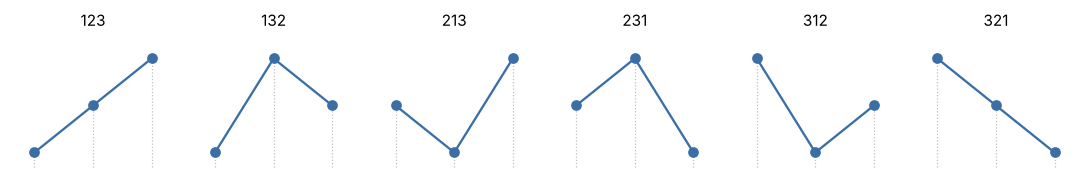

In [14]:
# Figura 3.14 — los seis patrones ordinales para D = 3
pat = list(itertools.permutations(range(3)))
fig, ax = plt.subplots(1, 6, figsize=(10, 1.8), sharey=True)
for x, p_ in zip(ax, pat):
    y = np.array(p_)                    # rango de cada una de las tres muestras
    for k in range(3):
        x.plot([k, k], [-.3, y[k]], ":", color="0.75", lw=.8)
    x.plot([0, 1, 2], y, "-o", color="#3b6ea5"); x.set_title("".join(str(k + 1) for k in p_), fontsize=10)
    x.set_xticks([]); x.set_yticks([]); x.set_xlim(-.4, 2.4); x.set_ylim(-.5, 2.5); x.grid(False)
    for lado in x.spines.values():
        lado.set_visible(False)
fig.tight_layout(); fig.savefig(OUT / "figura_3_14_patrones_ordinales.png", dpi=200); plt.show()

Entropía H                   NDBT2 = 0.905 ± 0.009 | DBT2 = 0.825 ± 0.024 | U = 0, p = 0.0079 | t = -6.83, p = 0.0009 | d = -4.32
Complejidad C                NDBT2 = 0.082 ± 0.007 | DBT2 = 0.140 ± 0.016 | U = 25, p = 0.0079 | t = 7.47, p = 0.0004 | d = 4.73


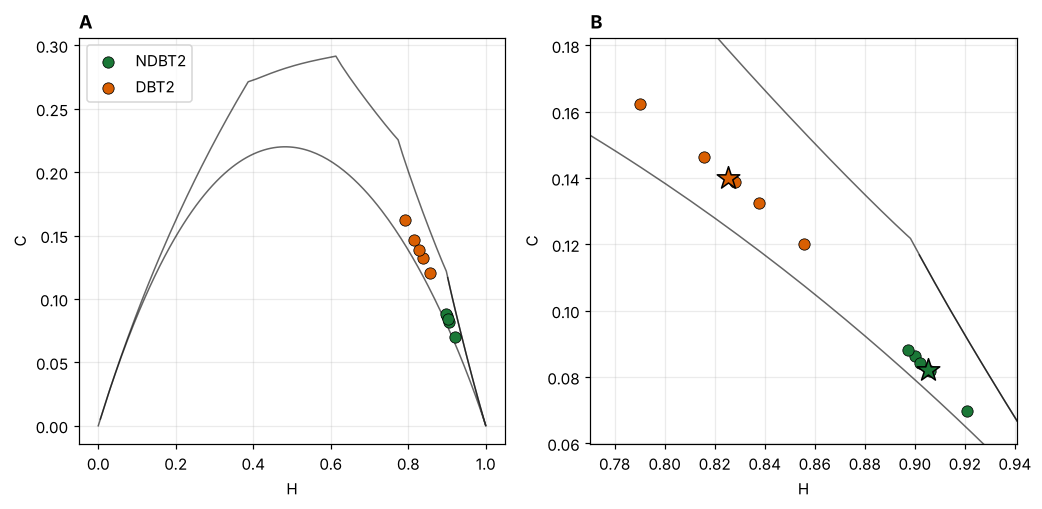

In [15]:
hc = {k: ordinal.hxc(v) for k, v in G.items()}
hc_nd = np.array([hc["NDBT2", i] for i in S_IDS]); hc_d = np.array([hc["DBT2", i] for i in E_REP])
RES["H"] = compara(hc_nd[:, 0], hc_d[:, 0], "Entropía H")
RES["C"] = compara(hc_nd[:, 1], hc_d[:, 1], "Complejidad C")
hmin, cmin, hmax, cmax = ordinal.curvas_limite(3)
fig, axs = plt.subplots(1, 2, figsize=(11, 4.8))
for a in axs:
    a.plot(hmax, cmax, "k-", lw=1, alpha=.6); a.plot(hmin, cmin, "k-", lw=1, alpha=.6)
    a.scatter(*hc_nd.T, c=C_ND, s=55, ec="k", lw=.5, label="NDBT2", zorder=3)
    a.scatter(*hc_d.T, c=C_D, s=55, ec="k", lw=.5, label="DBT2", zorder=3)
    a.set_xlabel("H"); a.set_ylabel("C")
axs[0].legend(loc="upper left"); axs[0].set_title("A", loc="left", fontweight="bold")
axs[1].scatter(*hc_nd.mean(0), c=C_ND, s=240, marker="*", ec="k", zorder=4)
axs[1].scatter(*hc_d.mean(0), c=C_D, s=240, marker="*", ec="k", zorder=4)
todo = np.vstack([hc_nd, hc_d]); axs[1].set_xlim(todo[:, 0].min() - .02, todo[:, 0].max() + .02)
axs[1].set_ylim(max(0, todo[:, 1].min() - .01), todo[:, 1].max() + .02); axs[1].set_title("B", loc="left", fontweight="bold")
fig.savefig(OUT / "figura_3_15_plano_HxC.png", dpi=200, bbox_inches="tight"); plt.show()

## 7. Norma del vector estacionario de la OPTM (Sec. 3.5.4, Tabla 3.5)

In [16]:
v = {k: ordinal.norma_estacionaria(x, "secuencial") for k, x in G.items()}
tabla_35 = pd.DataFrame({"Sujeto": range(1, 6),
                         "Stat_MS (NDBT2)": [v["NDBT2", i] for i in S_IDS],
                         "Diagnóstico (NDBT2)": [ordinal.clasificar_norma(v["NDBT2", i]) for i in S_IDS],
                         "Sujeto DBT2": E_REP,
                         "Stat_MS (DBT2)": [v["DBT2", i] for i in E_REP],
                         "Diagnóstico (DBT2)": [ordinal.clasificar_norma(v["DBT2", i]) for i in E_REP]})
tabla_35.round(4).to_csv(OUT / "tabla_3_5_optm.csv", index=False)
cuenta_19 = pd.Series([ordinal.clasificar_norma(v["DBT2", i]) for i in E_IDS]).value_counts().to_dict()
print("DBT2 completo (19):", cuenta_19)
tabla_35.round(4)

DBT2 completo (19): {'DBT2': 16, 'dudoso': 3}


,Sujeto,Stat_MS (NDBT2),Diagnóstico (NDBT2),Sujeto DBT2,Stat_MS (DBT2),Diagnóstico (DBT2)
0,1,0.4820,NDBT2,18,0.5098,DBT2
1,2,0.4674,NDBT2,2,0.5354,DBT2
2,3,0.4845,NDBT2,14,0.5206,DBT2
3,4,0.4768,NDBT2,17,0.5268,DBT2
4,5,0.4821,NDBT2,6,0.5506,DBT2


## 8. Reconstrucción del espacio de fases (Sec. 3.6, Figs. 3.16–3.17)
Información mutua promedio con bins por cuantiles y falsos vecinos más cercanos (criterio
de Kennel, cociente > 15). La tesis adopta τ_emb = 4 muestras (60 min) y m_emb = 4.

NDBT2-01: FNN (%) para m = 1…7: [38.5 15.9 10.   3.8  1.1  0.2  0. ]
DBT2-05: FNN (%) para m = 1…7: [76.3 36.4 10.4  2.4  0.   0.   0. ]


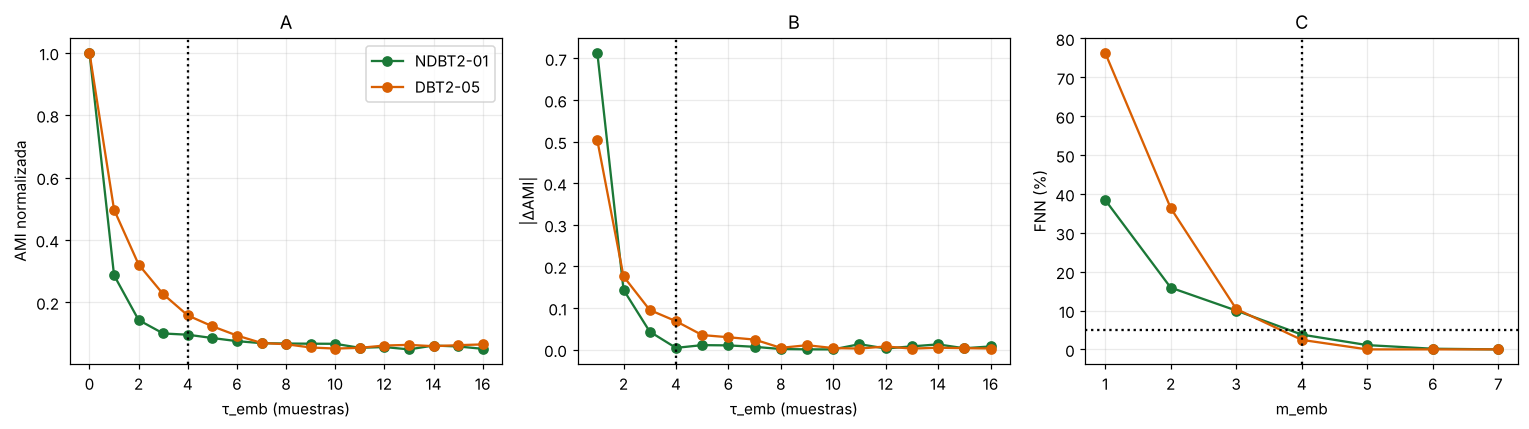

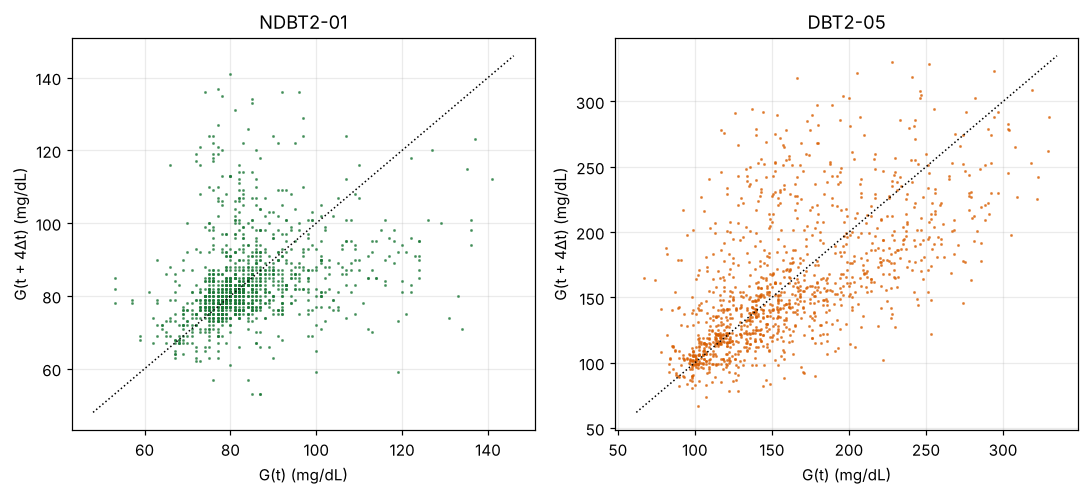

In [17]:
TAU_EMB, M_EMB = 4, 4
ejemplos = [("NDBT2", 1), ("DBT2", 5)]
fig, ax = plt.subplots(1, 3, figsize=(14, 4))
for (grp, i), c in zip(ejemplos, [C_ND, C_D]):
    ami = no_lineal.informacion_mutua(G[grp, i], 16)
    fnn = no_lineal.falsos_vecinos(G[grp, i], TAU_EMB, 7)
    ax[0].plot(ami, "o-", color=c, label=f"{grp}-{i:02d}")
    ax[1].plot(np.arange(1, len(ami)), np.abs(np.diff(ami)), "o-", color=c)
    ax[2].plot(np.arange(1, 8), 100 * fnn, "o-", color=c)
    print(f"{grp}-{i:02d}: FNN (%) para m = 1…7:", np.round(100 * fnn, 1))
    RES[f"fnn_{grp}"] = fnn
for a in ax[:2]: a.axvline(TAU_EMB, color="k", ls=":")
ax[2].axhline(5, color="k", ls=":"); ax[2].axvline(M_EMB, color="k", ls=":")
ax[0].set(xlabel="τ_emb (muestras)", ylabel="AMI normalizada", title="A"); ax[0].legend()
ax[1].set(xlabel="τ_emb (muestras)", ylabel="|ΔAMI|", title="B"); ax[2].set(xlabel="m_emb", ylabel="FNN (%)", title="C")
fig.tight_layout(); fig.savefig(OUT / "figura_3_16_incrustacion.png", dpi=200); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(10, 4.6))
for a, (grp, i), c in zip(ax, ejemplos, [C_ND, C_D]):
    x = G[grp, i]; a.plot(x[:-TAU_EMB], x[TAU_EMB:], ".", ms=2, color=c, alpha=.6)
    lim = [x.min() - 5, x.max() + 5]; a.plot(lim, lim, "k:", lw=1)
    a.set(xlabel="G(t) (mg/dL)", ylabel=f"G(t + {TAU_EMB}Δt) (mg/dL)", title=f"{grp}-{i:02d}")
fig.tight_layout(); fig.savefig(OUT / "figura_3_17_takens.png", dpi=200); plt.show()

## Verificación contra la tesis
`✔` indica coincidencia con el valor publicado al redondeo informado en el texto.

In [18]:
def fila(dato, publicado, obtenido, tol):
    return dict(Dato=dato, Tesis=publicado, Reproducido=round(float(obtenido), 4),
                Coincide="✔" if abs(float(obtenido) - publicado) <= tol else "✘")

ver = pd.DataFrame([
    fila("βc NDBT2 (banda confiable)", 1.28, RES["bc"]["nd_media"], .005),
    fila("βc DBT2 (banda confiable)", 2.60, RES["bc"]["db_media"], .01),
    fila("Submuestreo βc: Δ mediana", 1.29, np.median(RES["bc_sub"]), .01),
    fila("Submuestreo βc: % significativas", 100, 100 * np.mean(RES["bc_sub_p"] < .05), .1),
    fila("DFA G(t) NDBT2", 0.818, RES["dfa_G"]["nd_media"], .0005),
    fila("DFA G(t) DBT2", 0.895, RES["dfa_G"]["db_media"], .0005),
    fila("DFA G(t) Mann–Whitney p", 0.55, RES["dfa_G"]["p_MW"], .005),
    fila("DFA residuo NDBT2", 0.294, RES["dfa_R"]["nd_media"], .0005),
    fila("DFA residuo DBT2", 0.374, RES["dfa_R"]["db_media"], .0005),
    fila("DFA residuo d de Cohen", 2.7, RES["dfa_R"]["d"], .05),
    fila("DFA submuestreo G(t) % signif.", 2.3, RES["dfa_sub"][0], .05),
    fila("DFA submuestreo residuo % signif.", 73.7, RES["dfa_sub"][1], .05),
    fila("β de S(t) NDBT2", 0.12, RES["bS"]["nd_media"], .005),
    fila("β de S(t) DBT2", 1.28, RES["bS"]["db_media"], .005),
    fila("β de S(t) d de Cohen", 6.1, RES["bS"]["d"], .05),
    fila("λ_max NDBT2 [1/h]", 0.274, RES["lle"]["nd_media"], .0005),
    fila("λ_max DBT2 [1/h]", 0.398, RES["lle"]["db_media"], .0005),
    fila("H NDBT2", 0.905, RES["H"]["nd_media"], .0005),
    fila("H DBT2", 0.825, RES["H"]["db_media"], .0005),
    fila("C NDBT2", 0.082, RES["C"]["nd_media"], .0005),
    fila("C DBT2", 0.140, RES["C"]["db_media"], .0005),
    fila("Stat_MS NDBT2-01", 0.4820, v["NDBT2", 1], .00005),
    fila("Stat_MS DBT2 (máximo del subconjunto)", 0.5506, max(v["DBT2", i] for i in E_REP), .00005),
    fila("DBT2 completo clasificados 'DBT2'", 16, cuenta_19.get("DBT2", 0), 0),
    fila("Ventanas compatibles con ingesta (DBT2-05)", 31, RES["ingesta"][0], 0),
    fila("  de ellas fuertes", 8, RES["ingesta"][1].get("fuerte", 0), 0),
    fila("  de ellas moderadas", 9, RES["ingesta"][1].get("moderada", 0), 0),
    fila("  de ellas posibles", 14, RES["ingesta"][1].get("posible", 0), 0),
    fila("  ΔG_max medio de las fuertes (mg/dL)", 155.3, tabla_ing[tabla_ing.categoria == "fuerte"].delta_g_max.mean(), .0501),
    fila("  I_S medio de las fuertes", 0.77, tabla_ing[tabla_ing.categoria == "fuerte"].I_S.mean(), .005),
    fila("  ΔG_max medio de las moderadas (mg/dL)", 135.6, tabla_ing[tabla_ing.categoria == "moderada"].delta_g_max.mean(), .05),
    fila("  I_S medio de las moderadas", 0.68, tabla_ing[tabla_ing.categoria == "moderada"].I_S.mean(), .005),
    fila("Alba: ΔG día 4 (mg/dL)", 148, alba[3].delta_g, 0),
    fila("Alba: I_S día 4", 0.81, alba[3].I_S, .005),
    fila("Alba DBT2-05: días fuertes", 4, (alba5.categoria == "fuerte").sum(), 0),
    fila("Alba DBT2-05: ΔG día 3 (mg/dL)", 107, alba5[alba5.dia == 3].delta_g.iloc[0], 0),
    fila("Alba DBT2-05: ΔG día 8 (mg/dL)", 132, alba5[alba5.dia == 8].delta_g.iloc[0], 0),
    fila("Alba DBT2-05: ΔG día 9 (mg/dL)", 120, alba5[alba5.dia == 9].delta_g.iloc[0], 0),
    fila("Alba DBT2-05: ΔG día 12 (mg/dL)", -1, alba5[alba5.dia == 12].delta_g.iloc[0], 0),
    fila("Alba DBT2-05: días moderados", 5, (alba5.categoria == "moderada").sum(), 0),
    fila("Alba DBT2-05: días posibles", 2, (alba5.categoria == "posible").sum(), 0),
    fila("Alba DBT2-05: I_S día 12", -0.20, alba5[alba5.dia == 12].I_S.iloc[0], .005),
    fila("Sujetos con hipoglucemia nocturna", 9, RES["hipo"][0], 0),
    fila("Ventanas con ascenso tras mínimo < 70 mg/dL", 23, RES["hipo"][1], 0),
    fila("  de ellas con mínimo < 54 mg/dL", 3, RES["hipo"][2], 0),
    fila("  mínimo nocturno (mg/dL)", 40, RES["hipo"][3], 0),
    fila("DBT2-05: mínimo nocturno 22–08 h (mg/dL)", 83, G12[5][((np.arange(1152) % 96) >= 88) | ((np.arange(1152) % 96) < 32)].min(), 0),
    fila("βc DE NDBT2", 0.16, RES["bc"]["nd_de"], .005), fila("βc DE DBT2", 0.16, RES["bc"]["db_de"], .005),
    fila("βc Mann–Whitney U", 25, RES["bc"]["U"], 0), fila("βc Mann–Whitney p", 0.008, RES["bc"]["p_MW"], .0005),
    fila("βc t de Welch", 12.8, RES["bc"]["t"], .05), fila("βc d de Cohen", 8.1, RES["bc"]["d"], .05),
    fila("Δβc banda confiable", 1.32, RES["bc"]["db_media"] - RES["bc"]["nd_media"], .005),
    fila("βc banda completa NDBT2", 2.06, RES["bc_full"]["nd_media"], .005), fila("  DE", 0.14, RES["bc_full"]["nd_de"], .005),
    fila("βc banda completa DBT2", 2.55, RES["bc_full"]["db_media"], .005), fila("  DE", 0.17, RES["bc_full"]["db_de"], .005),
    fila("Δβc banda completa", 0.49, RES["bc_full"]["db_media"] - RES["bc_full"]["nd_media"], .005),
    fila("Submuestreo βc: Δ mínima", 0.96, np.min(RES["bc_sub"]), .005), fila("Submuestreo βc: Δ máxima", 1.73, np.max(RES["bc_sub"]), .005),
    fila("Submuestreo βc: p máximo", 0.012, np.max(RES["bc_sub_p"]), .0005),
    fila("DFA G(t) DE NDBT2", 0.052, RES["dfa_G"]["nd_de"], .0005), fila("DFA G(t) DE DBT2", 0.121, RES["dfa_G"]["db_de"], .0005),
    fila("DFA residuo DE NDBT2", 0.016, RES["dfa_R"]["nd_de"], .0005), fila("DFA residuo DE DBT2", 0.038, RES["dfa_R"]["db_de"], .0005),
    fila("DFA residuo Mann–Whitney p", 0.008, RES["dfa_R"]["p_MW"], .0005),
    fila("DFA submuestreo residuo: Δα mediana", 0.074, RES["dfa_sub"][2], .0005),
    fila("Δβ de S(t) banda confiable", 1.16, RES["bS"]["db_media"] - RES["bS"]["nd_media"], .005),
    fila("Δβ de S(t) banda completa", 0.55, RES["bS_full"], .005),
    fila("β de S(t) Mann–Whitney U", 25, RES["bS"]["U"], 0), fila("β de S(t) t de Welch", 9.6, RES["bS"]["t"], .05),
    fila("λ_max DE NDBT2", 0.017, RES["lle"]["nd_de"], .0005), fila("λ_max DE DBT2", 0.041, RES["lle"]["db_de"], .0005),
    fila("T_L NDBT2 [h]", 3.66, tl_nd.mean(), .005), fila("T_L DBT2 [h]", 2.53, tl_d.mean(), .005),
    fila("T_L DE NDBT2", 0.22, tl_nd.std(ddof=1), .005), fila("T_L DE DBT2", 0.27, tl_d.std(ddof=1), .005),
    fila("λ_max Mann–Whitney p", 0.008, RES["lle"]["p_MW"], .0005), fila("λ_max t de Welch", 6.3, RES["lle"]["t"], .05),
    fila("λ_max d de Cohen", 4.0, RES["lle"]["d"], .05), fila("λ_max submuestreo % signif.", 100, 100 * np.mean(RES["lle_sub"][1] < .05), .05),
    *[fila(f"Stat_MS NDBT2-{k:02d}", pub, v["NDBT2", k], .00005) for k, pub in zip(S_IDS, (0.4820, 0.4674, 0.4845, 0.4768, 0.4821))],
    *[fila(f"Stat_MS DBT2-{k:02d} (subconjunto)", pub, v["DBT2", k], .00005) for k, pub in zip(E_REP, (0.5098, 0.5354, 0.5206, 0.5268, 0.5506))],
    fila("DBT2 completo en zona dudosa", 3, cuenta_19.get("Dudoso", cuenta_19.get("dudoso", 0)), 0),
    fila("FNN NDBT2-01 < 5 % en m = 4", 1, float(RES["fnn_NDBT2"][3] < .05), 0),
    fila("FNN DBT2-05 < 5 % en m = 4", 1, float(RES["fnn_DBT2"][3] < .05), 0),
])
ver.to_csv(OUT / "verificacion_cap3.csv", index=False)
ver

,Dato,Tesis,Reproducido,Coincide
0,βc NDBT2 (banda confiable),1.2800,1.2835,✔
1,βc DBT2 (banda confiable),2.6000,2.6047,✔
2,Submuestreo βc: Δ mediana,1.2900,1.2946,✔
3,Submuestreo βc: % significativas,100.0000,100.0000,✔
4,DFA G(t) NDBT2,0.8180,0.8177,✔
...,...,...,...,...
90,Stat_MS DBT2-17 (subconjunto),0.5268,0.5268,✔
91,Stat_MS DBT2-06 (subconjunto),0.5506,0.5506,✔
92,DBT2 completo en zona dudosa,3.0000,3.0000,✔
93,FNN NDBT2-01 < 5 % en m = 4,1.0000,1.0000,✔
